In [1]:
# ============================================================
# MODULE 4 — WAREHOUSE CONGESTION
# CELL 1 — GENERATE SYNTHETIC DATASET
# ============================================================

import os
import json
import pickle
import zipfile
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

SEED = 42
N_ROWS = 25_000

np.random.seed(SEED)

# ------------------------------------------------------------
# OUTPUT PATHS
# ------------------------------------------------------------

DATA_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_final_dataset.csv"
)

TRAIN_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_train.csv"
)

VAL_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_validation.csv"
)

TEST_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_test.csv"
)


# ------------------------------------------------------------
# GENERATOR
# ------------------------------------------------------------

def generate_warehouse_data(
    n_rows=25_000,
    seed=42
):

    rng = np.random.default_rng(seed)

    # --------------------------------------------------------
    # TIME
    # --------------------------------------------------------

    timestamps = pd.date_range(
        start="2025-01-01 00:00:00",
        periods=n_rows,
        freq="30min"
    )

    hour = timestamps.hour

    day_of_week = (
        timestamps.dayofweek
    )

    is_weekend = (
        day_of_week >= 5
    ).astype(int)

    # --------------------------------------------------------
    # DAILY PATTERN
    # --------------------------------------------------------

    hour_angle = (
        2 * np.pi * hour / 24
    )

    daily_pattern = (
        0.5
        + 0.5 * np.sin(
            hour_angle - np.pi / 2
        )
    )

    # --------------------------------------------------------
    # SHIFTS
    # --------------------------------------------------------

    shift = np.select(
        [
            hour < 8,
            (hour >= 8) & (hour < 16),
            hour >= 16
        ],
        [
            0,
            1,
            2
        ]
    )

    base_staff = np.select(
        [
            shift == 0,
            shift == 1,
            shift == 2
        ],
        [
            16,
            30,
            24
        ]
    ).astype(float)

    # Weekend staffing reduction
    base_staff -= (
        is_weekend * 6
    )

    # Shift changes
    shift_change = (
        (
            (hour == 7)
            | (hour == 15)
            | (hour == 23)
        )
        .astype(int)
    )

    base_staff -= (
        shift_change * 4
    )

    staff_count = (
        base_staff
        + rng.normal(
            0,
            2.5,
            n_rows
        )
    )

    staff_count = np.clip(
        np.round(staff_count),
        4,
        40
    ).astype(int)

    # --------------------------------------------------------
    # ORDER VOLUME
    # --------------------------------------------------------

    order_base = (
        75
        + 35 * daily_pattern
    )

    business_hours = (
        (
            (hour >= 7)
            & (hour <= 19)
        )
        .astype(float)
    )

    order_base += (
        30 * business_hours
    )

    order_base -= (
        20 * is_weekend
    )

    order_volume = rng.poisson(
        np.clip(
            order_base,
            5,
            None
        )
    )

    # --------------------------------------------------------
    # TRUCK ARRIVALS
    # --------------------------------------------------------

    truck_rate = (
        4
        + 6 * business_hours
        + 4 * (
            order_volume
            / max(
                order_volume.mean(),
                1
            )
        )
    )

    truck_arrivals = rng.poisson(
        np.clip(
            truck_rate,
            1,
            None
        )
    )

    # --------------------------------------------------------
    # BURST EVENTS
    # --------------------------------------------------------

    burst_probability = 0.035

    burst_event = (
        rng.random(n_rows)
        < burst_probability
    ).astype(int)

    burst_strength = np.where(
        burst_event == 1,
        rng.uniform(
            1.5,
            2.5,
            n_rows
        ),
        1.0
    )

    order_volume = np.round(
        order_volume
        * burst_strength
    ).astype(int)

    truck_arrivals = np.round(
        truck_arrivals
        * burst_strength
    ).astype(int)

    # --------------------------------------------------------
    # TEMPORAL PRESSURE
    # --------------------------------------------------------

    pressure = np.zeros(
        n_rows
    )

    for i in range(n_rows):

        current_pressure = (
            0.004
            * order_volume[i]

            + 0.035
            * truck_arrivals[i]

            - 0.035
            * staff_count[i]
        )

        if i > 0:

            current_pressure += (
                0.35
                * pressure[i - 1]
            )

        if burst_event[i]:

            current_pressure += 0.6

        pressure[i] = (
            current_pressure
        )

    # --------------------------------------------------------
    # DOCK UTILIZATION
    # --------------------------------------------------------

    utilization_base = (
        0.20

        + 0.0035
        * order_volume

        + 0.025
        * truck_arrivals

        + 0.15
        * business_hours
    )

    dock_utilization = (
        utilization_base
        + rng.normal(
            0,
            0.06,
            n_rows
        )
    )

    dock_utilization = np.clip(
        dock_utilization
        + 0.08
        * np.tanh(
            pressure - 0.5
        ),
        0.05,
        1.0
    )

    # --------------------------------------------------------
    # SYNTHETIC CONGESTION RISK
    # --------------------------------------------------------

    raw_risk = (
        -5.0

        + 4.8
        * dock_utilization

        + 0.018
        * order_volume

        + 0.075
        * truck_arrivals

        - 0.09
        * staff_count

        + 0.65
        * burst_event

        + 0.35
        * shift_change
    )

    # Temporal persistence
    temporal_component = np.zeros(
        n_rows
    )

    for i in range(
        1,
        n_rows
    ):

        temporal_component[i] = (
            0.25
            * temporal_component[i - 1]
        )

    raw_risk += (
        temporal_component
    )

    congestion_probability = (
        1
        / (
            1
            + np.exp(
                -raw_risk
            )
        )
    )

    # Add realistic uncertainty
    congestion_probability = np.clip(
        congestion_probability
        + rng.normal(
            0,
            0.04,
            n_rows
        ),
        0.001,
        0.999
    )

    # --------------------------------------------------------
    # TARGET
    # --------------------------------------------------------

    congestion = (
        rng.random(n_rows)
        < congestion_probability
    ).astype(int)

    # --------------------------------------------------------
    # DATAFRAME
    # --------------------------------------------------------

    df = pd.DataFrame({

        "timestamp":
            timestamps,

        "hour":
            hour,

        "day_of_week":
            day_of_week,

        "shift":
            shift,

        "shift_change":
            shift_change,

        "order_volume":
            order_volume,

        "truck_arrivals":
            truck_arrivals,

        "dock_utilization":
            dock_utilization,

        "staff_count":
            staff_count,

        "burst_event":
            burst_event,

        "congestion":
            congestion
    })

    return df


# ------------------------------------------------------------
# GENERATE
# ------------------------------------------------------------

df = generate_warehouse_data(
    n_rows=N_ROWS,
    seed=SEED
)

# ------------------------------------------------------------
# SAVE COMPLETE DATASET
# ------------------------------------------------------------

df.to_csv(
    DATA_PATH,
    index=False
)

# ------------------------------------------------------------
# CHRONOLOGICAL SPLIT
# ------------------------------------------------------------

n = len(df)

train_end = int(
    n * 0.70
)

val_end = int(
    n * 0.85
)

train_df = df.iloc[
    :train_end
].copy()

val_df = df.iloc[
    train_end:val_end
].copy()

test_df = df.iloc[
    val_end:
].copy()

train_df.to_csv(
    TRAIN_PATH,
    index=False
)

val_df.to_csv(
    VAL_PATH,
    index=False
)

test_df.to_csv(
    TEST_PATH,
    index=False
)


# ------------------------------------------------------------
# REPORT
# ------------------------------------------------------------

print("=" * 70)
print("WAREHOUSE CONGESTION DATASET CREATED")
print("=" * 70)

print(
    f"Total rows       : {len(df):,}"
)

print(
    f"Training rows    : {len(train_df):,}"
)

print(
    f"Validation rows  : {len(val_df):,}"
)

print(
    f"Testing rows     : {len(test_df):,}"
)

print(
    f"Congestion rate  : "
    f"{df['congestion'].mean():.2%}"
)

print("\nComplete dataset:")
print(DATA_PATH)

print("\nColumns:")
for column in df.columns:
    print(
        " •",
        column
    )

print("\nClass distribution:")
print(
    df["congestion"]
    .value_counts(
        normalize=True
    )
    .sort_index()
)

print("\nSample:")
display(
    df.head(10)
)

WAREHOUSE CONGESTION DATASET CREATED
Total rows       : 25,000
Training rows    : 17,500
Validation rows  : 3,750
Testing rows     : 3,750
Congestion rate  : 48.42%

Complete dataset:
/kaggle/working/warehouse_congestion_final_dataset.csv

Columns:
 • timestamp
 • hour
 • day_of_week
 • shift
 • shift_change
 • order_volume
 • truck_arrivals
 • dock_utilization
 • staff_count
 • burst_event
 • congestion

Class distribution:
congestion
0    0.5158
1    0.4842
Name: proportion, dtype: float64

Sample:


,timestamp,hour,day_of_week,shift,shift_change,order_volume,truck_arrivals,dock_utilization,staff_count,burst_event,congestion
0,2025-01-01 00:00:00,0,2,0,0,72,6,0.547661,17,0,0
1,2025-01-01 00:30:00,0,2,0,0,82,3,0.495617,13,0,0
2,2025-01-01 01:00:00,1,2,0,0,81,6,0.578483,18,0,1
3,2025-01-01 01:30:00,1,2,0,0,75,8,0.635247,18,0,1
4,2025-01-01 02:00:00,2,2,0,0,79,6,0.468773,11,0,0
5,2025-01-01 02:30:00,2,2,0,0,78,8,0.569906,13,0,0
6,2025-01-01 03:00:00,3,2,0,0,91,3,0.596696,16,0,0
7,2025-01-01 03:30:00,3,2,0,0,79,8,0.677311,15,0,0
8,2025-01-01 04:00:00,4,2,0,0,73,5,0.554144,16,0,0
9,2025-01-01 04:30:00,4,2,0,0,88,6,0.677898,14,0,1


Loaded 25,000 rows.

Data split:
Train: 17500
Validation: 3750
Test: 3750

Training XGBoost...
XGBoost training complete.

XGBoost Feature Importance:


,importance
dock_utilization,0.465116
order_volume,0.085780
burst_event,0.061153
trucks_per_staff,0.059191
orders_per_staff,0.055503
shift_change,0.048428
truck_arrivals,0.042444
hour_cos,0.033003
staff_count,0.032699
day_sin,0.031562



Selected features for LSTM:
1. dock_utilization
2. order_volume
3. burst_event
4. trucks_per_staff
5. orders_per_staff
6. shift_change
7. truck_arrivals
8. hour_cos

Saved: /kaggle/working/congestion_models/congestion_xgb.json
Saved: /kaggle/working/congestion_models/congestion_scaler.pkl

Sequence shapes:
X_train: (17489, 12, 8)
X_val: (3739, 12, 8)
X_test: (3739, 12, 8)

Class weights: {0: 1.0, 1: 1.0626253095883949}

LSTM architecture:


2026-10-08 12:03:02.750258: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 12, 64)         │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,649 (123.63 KB)

 Trainable params: 31,649 (123.63 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM...
Epoch 1/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.7345 - auc: 0.7744 - loss: 0.5805 - precision: 0.6978 - recall: 0.7979 - val_accuracy: 0.7649 - val_auc: 0.8243 - val_loss: 0.5125 - val_precision: 0.7148 - val_recall: 0.8524 - learning_rate: 0.0010
Epoch 2/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7625 - auc: 0.8203 - loss: 0.5286 - precision: 0.7223 - recall: 0.8289 - val_accuracy: 0.7668 - val_auc: 0.8392 - val_loss: 0.4979 - val_precision: 0.7177 - val_recall: 0.8507 - learning_rate: 0.0010
Epoch 3/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7660 - auc: 0.8284 - loss: 0.5202 - precision: 0.7258 - recall: 0.8313 - val_accuracy: 0.7665 - val_auc: 0.8404 - val_loss: 0.4955 - val_precision: 0.7180 - val_recall: 0.8491 - learning_rate: 0.0010
Epoch 4/50
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7683 - auc: 0.8303 - loss: 0.5174 - precision: 0.7288 - recall: 0.8315 - val_accuracy: 0.7697 - val_auc: 0.8420 -

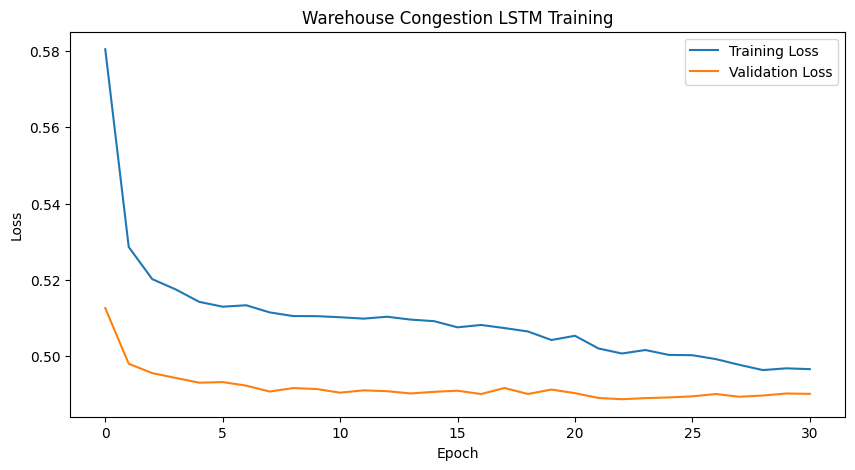

FINAL LSTM TEST RESULTS
ACCURACY    : 0.7662
PRECISION   : 0.7253
RECALL      : 0.8312
F1          : 0.7746
ROC_AUC     : 0.8371

Classification Report:
              precision    recall  f1-score   support

         Low       0.82      0.71      0.76      1932
        High       0.73      0.83      0.77      1807

    accuracy                           0.77      3739
   macro avg       0.77      0.77      0.77      3739
weighted avg       0.77      0.77      0.77      3739

Confusion Matrix:
[[1363  569]
 [ 305 1502]]

Saved: /kaggle/working/congestion_models/congestion_lstm.keras
Saved: /kaggle/working/congestion_models/congestion_features.json
Saved: /kaggle/working/congestion_models/congestion_metadata.json

TRAINING COMPLETE

Model artifacts:
 ✓ congestion_features.json
 ✓ congestion_lstm.keras
 ✓ congestion_metadata.json
 ✓ congestion_scaler.pkl
 ✓ congestion_xgb.json


In [2]:
# ============================================================
# MODULE 4 — WAREHOUSE CONGESTION
# CELL 2 — TRAIN XGBOOST + LSTM
# ============================================================

import os
import json
import pickle
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import tensorflow as tf


# ============================================================
# CONFIG
# ============================================================

SEED = 42

SEQUENCE_LENGTH = 12

TOP_K_FEATURES = 8

OUTPUT_DIR = (
    "/kaggle/working/"
    "congestion_models"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# LOAD FINAL DATASET
# ============================================================

DATA_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_final_dataset.csv"
)

df = pd.read_csv(
    DATA_PATH
)

print(
    f"Loaded {len(df):,} rows."
)


# ============================================================
# FEATURE ENGINEERING
# ============================================================

def create_features(df):

    df = df.copy()

    # Cyclic hour
    df["hour_sin"] = np.sin(
        2 * np.pi
        * df["hour"]
        / 24
    )

    df["hour_cos"] = np.cos(
        2 * np.pi
        * df["hour"]
        / 24
    )

    # Cyclic day
    df["day_sin"] = np.sin(
        2 * np.pi
        * df["day_of_week"]
        / 7
    )

    df["day_cos"] = np.cos(
        2 * np.pi
        * df["day_of_week"]
        / 7
    )

    # Orders per staff
    df["orders_per_staff"] = (
        df["order_volume"]
        / np.maximum(
            df["staff_count"],
            1
        )
    )

    # Trucks per staff
    df["trucks_per_staff"] = (
        df["truck_arrivals"]
        / np.maximum(
            df["staff_count"],
            1
        )
    )

    return df


df = create_features(
    df
)


# ============================================================
# CANDIDATE FEATURES
# ============================================================

candidate_features = [

    "order_volume",

    "dock_utilization",

    "staff_count",

    "truck_arrivals",

    "shift",

    "shift_change",

    "burst_event",

    "hour_sin",

    "hour_cos",

    "day_sin",

    "day_cos",

    "orders_per_staff",

    "trucks_per_staff"
]


# ============================================================
# CHRONOLOGICAL SPLIT
# ============================================================

n = len(df)

train_end = int(
    n * 0.70
)

val_end = int(
    n * 0.85
)

train_df = df.iloc[
    :train_end
].copy()

val_df = df.iloc[
    train_end:val_end
].copy()

test_df = df.iloc[
    val_end:
].copy()

print("\nData split:")

print(
    "Train:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)


# ============================================================
# XGBOOST
# ============================================================

positive = (
    train_df["congestion"]
    .sum()
)

negative = (
    len(train_df)
    - positive
)

scale_pos_weight = (
    negative
    / max(
        positive,
        1
    )
)

xgb_model = XGBClassifier(

    n_estimators=400,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.85,

    colsample_bytree=0.85,

    min_child_weight=3,

    reg_alpha=0.1,

    reg_lambda=1.0,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=
        scale_pos_weight,

    random_state=SEED,

    n_jobs=-1
)

print(
    "\nTraining XGBoost..."
)

xgb_model.fit(
    train_df[
        candidate_features
    ],
    train_df[
        "congestion"
    ]
)

print(
    "XGBoost training complete."
)


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importances = pd.Series(
    xgb_model.feature_importances_,
    index=candidate_features
).sort_values(
    ascending=False
)

print(
    "\nXGBoost Feature Importance:"
)

display(
    importances.to_frame(
        "importance"
    )
)


# ============================================================
# SELECT TOP FEATURES
# ============================================================

top_features = (
    importances
    .head(TOP_K_FEATURES)
    .index
    .tolist()
)

print(
    "\nSelected features for LSTM:"
)

for i, feature in enumerate(
    top_features,
    1
):

    print(
        f"{i}. {feature}"
    )


# ============================================================
# SAVE XGBOOST
# ============================================================

XGB_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_xgb.json"
)

xgb_model.save_model(
    XGB_PATH
)

print(
    "\nSaved:",
    XGB_PATH
)


# ============================================================
# SCALE FEATURES
# ============================================================

scaler = StandardScaler()

# IMPORTANT:
# Fit only on training data.

scaler.fit(
    train_df[
        top_features
    ]
)

SCALER_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_scaler.pkl"
)

with open(
    SCALER_PATH,
    "wb"
) as f:

    pickle.dump(
        scaler,
        f
    )

print(
    "Saved:",
    SCALER_PATH
)


# ============================================================
# CREATE SEQUENCES
# ============================================================

def create_sequences(
    df,
    features,
    scaler,
    start_idx,
    end_idx,
    sequence_length
):

    values = scaler.transform(
        df[
            features
        ]
    )

    target = (
        df["congestion"]
        .values
    )

    X = []
    y = []

    for i in range(
        start_idx
        + sequence_length
        - 1,
        end_idx
    ):

        start = (
            i
            - sequence_length
            + 1
        )

        X.append(
            values[
                start:i + 1
            ]
        )

        y.append(
            target[i]
        )

    return (
        np.asarray(
            X,
            dtype=np.float32
        ),
        np.asarray(
            y,
            dtype=np.float32
        )
    )


X_train, y_train = create_sequences(
    df,
    top_features,
    scaler,
    0,
    train_end,
    SEQUENCE_LENGTH
)

X_val, y_val = create_sequences(
    df,
    top_features,
    scaler,
    train_end,
    val_end,
    SEQUENCE_LENGTH
)

X_test, y_test = create_sequences(
    df,
    top_features,
    scaler,
    val_end,
    n,
    SEQUENCE_LENGTH
)

print(
    "\nSequence shapes:"
)

print(
    "X_train:",
    X_train.shape
)

print(
    "X_val:",
    X_val.shape
)

print(
    "X_test:",
    X_test.shape
)


# ============================================================
# CLASS WEIGHTS
# ============================================================

positive = np.sum(
    y_train == 1
)

negative = np.sum(
    y_train == 0
)

positive_weight = (
    negative
    / max(
        positive,
        1
    )
)

class_weight = {

    0: 1.0,

    1: float(
        positive_weight
    )
}

print(
    "\nClass weights:",
    class_weight
)


# ============================================================
# LSTM MODEL
# ============================================================

lstm_model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(
            SEQUENCE_LENGTH,
            len(top_features)
        )
    ),

    tf.keras.layers.LSTM(
        64,
        return_sequences=True
    ),

    tf.keras.layers.Dropout(
        0.25
    ),

    tf.keras.layers.LSTM(
        32
    ),

    tf.keras.layers.Dropout(
        0.20
    ),

    tf.keras.layers.Dense(
        16,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])


lstm_model.compile(

    optimizer=
    tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=
    "binary_crossentropy",

    metrics=[

        tf.keras.metrics.BinaryAccuracy(
            name="accuracy"
        ),

        tf.keras.metrics.AUC(
            name="auc"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)


print(
    "\nLSTM architecture:"
)

lstm_model.summary()


# ============================================================
# CALLBACKS
# ============================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=8,

        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=4,

        min_lr=1e-6
    )
]


# ============================================================
# TRAIN LSTM
# ============================================================

print(
    "\nTraining LSTM..."
)

history = lstm_model.fit(

    X_train,

    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=50,

    batch_size=64,

    class_weight=
        class_weight,

    callbacks=
        callbacks,

    verbose=1
)

print(
    "\nLSTM training complete."
)


# ============================================================
# TRAINING CURVE
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Warehouse Congestion LSTM Training"
)

plt.legend()

plt.show()


# ============================================================
# EVALUATION
# ============================================================

def evaluate_model(
    model,
    X,
    y
):

    probabilities = (
        model.predict(
            X,
            verbose=0
        )
        .ravel()
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        y,
        predictions
    )

    precision = precision_score(
        y,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y,
        predictions,
        zero_division=0
    )

    auc = roc_auc_score(
        y,
        probabilities
    )

    return (
        probabilities,
        predictions,
        {
            "accuracy":
                float(accuracy),

            "precision":
                float(precision),

            "recall":
                float(recall),

            "f1":
                float(f1),

            "roc_auc":
                float(auc)
        }
    )


(
    test_probabilities,
    test_predictions,
    test_metrics
) = evaluate_model(
    lstm_model,
    X_test,
    y_test
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 70)
print("FINAL LSTM TEST RESULTS")
print("=" * 70)

for metric, value in (
    test_metrics.items()
):

    print(
        f"{metric.upper():<12}: "
        f"{value:.4f}"
    )

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Low",
            "High"
        ],
        zero_division=0
    )
)

print(
    "Confusion Matrix:"
)

print(
    confusion_matrix(
        y_test,
        test_predictions
    )
)


# ============================================================
# SAVE LSTM
# ============================================================

LSTM_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_lstm.keras"
)

lstm_model.save(
    LSTM_PATH
)

print(
    "\nSaved:",
    LSTM_PATH
)


# ============================================================
# SAVE FEATURE CONFIG
# ============================================================

FEATURES_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_features.json"
)

feature_config = {

    "candidate_features":
        candidate_features,

    "selected_features":
        top_features,

    "sequence_length":
        SEQUENCE_LENGTH
}

with open(
    FEATURES_PATH,
    "w"
) as f:

    json.dump(
        feature_config,
        f,
        indent=4
    )

print(
    "Saved:",
    FEATURES_PATH
)


# ============================================================
# SAVE METADATA
# ============================================================

METADATA_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_metadata.json"
)

metadata = {

    "module":
        "warehouse_congestion",

    "model_type":
        "XGBoost feature selection + LSTM sequence classifier",

    "sequence_length":
        SEQUENCE_LENGTH,

    "threshold":
        0.50,

    "metrics":
        test_metrics,

    "train_rows":
        int(len(train_df)),

    "validation_rows":
        int(len(val_df)),

    "test_rows":
        int(len(test_df)),

    "selected_features":
        top_features
}

with open(
    METADATA_PATH,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

print(
    "Saved:",
    METADATA_PATH
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    "\nModel artifacts:"
)

for filename in sorted(
    os.listdir(
        OUTPUT_DIR
    )
):

    print(
        " ✓",
        filename
    )

In [3]:
# ============================================================
# MODULE 4 — WAREHOUSE CONGESTION
# CELL 3 — PREDICTION / INFERENCE
# ============================================================

import os
import json
import pickle

import numpy as np
import pandas as pd

import tensorflow as tf


# ============================================================
# PATHS
# ============================================================

OUTPUT_DIR = (
    "/kaggle/working/"
    "congestion_models"
)

LSTM_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_lstm.keras"
)

SCALER_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_scaler.pkl"
)

FEATURES_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_features.json"
)

METADATA_PATH = os.path.join(
    OUTPUT_DIR,
    "congestion_metadata.json"
)


# ============================================================
# LOAD TRAINED ARTIFACTS
# ============================================================

lstm_model = tf.keras.models.load_model(
    LSTM_PATH
)

with open(
    SCALER_PATH,
    "rb"
) as f:

    scaler = pickle.load(
        f
    )

with open(
    FEATURES_PATH,
    "r"
) as f:

    feature_config = json.load(
        f
    )

with open(
    METADATA_PATH,
    "r"
) as f:

    metadata = json.load(
        f
    )


selected_features = (
    feature_config[
        "selected_features"
    ]
)

sequence_length = (
    feature_config[
        "sequence_length"
    ]
)

threshold = metadata.get(
    "threshold",
    0.50
)


print("=" * 70)
print("WAREHOUSE CONGESTION MODEL LOADED")
print("=" * 70)

print(
    "Selected features:"
)

for feature in selected_features:
    print(
        " •",
        feature
    )

print(
    "\nSequence length:",
    sequence_length
)

print(
    "Decision threshold:",
    threshold
)


# ============================================================
# FEATURE PREPARATION
# ============================================================

def prepare_prediction_features(
    df
):

    df = df.copy()

    df["hour_sin"] = np.sin(
        2 * np.pi
        * df["hour"]
        / 24
    )

    df["hour_cos"] = np.cos(
        2 * np.pi
        * df["hour"]
        / 24
    )

    df["day_sin"] = np.sin(
        2 * np.pi
        * df["day_of_week"]
        / 7
    )

    df["day_cos"] = np.cos(
        2 * np.pi
        * df["day_of_week"]
        / 7
    )

    df["orders_per_staff"] = (
        df["order_volume"]
        / np.maximum(
            df["staff_count"],
            1
        )
    )

    df["trucks_per_staff"] = (
        df["truck_arrivals"]
        / np.maximum(
            df["staff_count"],
            1
        )
    )

    return df


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def predict_congestion(
    observations
):

    if isinstance(
        observations,
        pd.DataFrame
    ):

        input_df = observations.copy()

    else:

        input_df = pd.DataFrame(
            observations
        )

    # --------------------------------------------------------
    # REQUIRED INPUTS
    # --------------------------------------------------------

    required_columns = [

        "hour",

        "day_of_week",

        "shift",

        "shift_change",

        "order_volume",

        "truck_arrivals",

        "dock_utilization",

        "staff_count",

        "burst_event"
    ]

    missing = [
        col
        for col in required_columns
        if col not in input_df.columns
    ]

    if missing:

        raise ValueError(
            "Missing columns: "
            + ", ".join(
                missing
            )
        )

    if len(input_df) < sequence_length:

        raise ValueError(
            f"Need at least "
            f"{sequence_length} "
            f"time observations."
        )

    # --------------------------------------------------------
    # FEATURE ENGINEERING
    # --------------------------------------------------------

    input_df = (
        prepare_prediction_features(
            input_df
        )
    )

    # --------------------------------------------------------
    # LAST 12 TIMESTEPS
    # --------------------------------------------------------

    sequence_df = (
        input_df
        .tail(
            sequence_length
        )
    )

    # --------------------------------------------------------
    # SCALE
    # --------------------------------------------------------

    scaled = scaler.transform(
        sequence_df[
            selected_features
        ]
    )

    X = np.expand_dims(
        scaled.astype(
            np.float32
        ),
        axis=0
    )

    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    risk = float(
        lstm_model.predict(
            X,
            verbose=0
        )[0][0]
    )

    risk = float(
        np.clip(
            risk,
            0.0,
            1.0
        )
    )

    # --------------------------------------------------------
    # STATUS
    # --------------------------------------------------------

    status = (
        "high"
        if risk >= threshold
        else "low"
    )

    return {

        "congestion_risk":
            round(
                risk,
                4
            ),

        "status":
            status,

        "threshold":
            threshold
    }


# ============================================================
# HIGH-CONGESTION TEST
# ============================================================

high_scenario = []

for i in range(
    sequence_length
):

    high_scenario.append({

        "hour":
            (8 + i) % 24,

        "day_of_week":
            2,

        "shift":
            1,

        "shift_change":
            0,

        "order_volume":
            130 + i * 6,

        "truck_arrivals":
            12 + i,

        "dock_utilization":
            min(
                0.65
                + i * 0.025,
                0.98
            ),

        "staff_count":
            max(
                30 - i,
                12
            ),

        "burst_event":
            1
            if i >= 8
            else 0
    })


high_result = predict_congestion(
    high_scenario
)

print()
print("=" * 70)
print("HIGH-CONGESTION SCENARIO")
print("=" * 70)

print(
    json.dumps(
        high_result,
        indent=4
    )
)


# ============================================================
# LOW-CONGESTION TEST
# ============================================================

low_scenario = []

for i in range(
    sequence_length
):

    low_scenario.append({

        "hour":
            (2 + i) % 24,

        "day_of_week":
            2,

        "shift":
            0,

        "shift_change":
            0,

        "order_volume":
            35 + i,

        "truck_arrivals":
            2,

        "dock_utilization":
            0.20
            + i * 0.005,

        "staff_count":
            30,

        "burst_event":
            0
    })


low_result = predict_congestion(
    low_scenario
)

print()
print("=" * 70)
print("LOW-CONGESTION SCENARIO")
print("=" * 70)

print(
    json.dumps(
        low_result,
        indent=4
    )
)


# ============================================================
# PACKAGE EVERYTHING
# ============================================================

ZIP_PATH = (
    "/kaggle/working/"
    "warehouse_congestion_complete.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    # Final dataset
    zipf.write(
        "/kaggle/working/"
        "warehouse_congestion_final_dataset.csv",
        arcname=
        "warehouse_congestion_final_dataset.csv"
    )

    # Train / validation / test
    zipf.write(
        "/kaggle/working/"
        "warehouse_congestion_train.csv",
        arcname=
        "warehouse_congestion_train.csv"
    )

    zipf.write(
        "/kaggle/working/"
        "warehouse_congestion_validation.csv",
        arcname=
        "warehouse_congestion_validation.csv"
    )

    zipf.write(
        "/kaggle/working/"
        "warehouse_congestion_test.csv",
        arcname=
        "warehouse_congestion_test.csv"
    )

    # Model artifacts
    for filename in os.listdir(
        OUTPUT_DIR
    ):

        filepath = os.path.join(
            OUTPUT_DIR,
            filename
        )

        zipf.write(
            filepath,
            arcname=os.path.join(
                "models",
                filename
            )
        )


print()
print("=" * 70)
print("FINAL PROJECT PACKAGE CREATED")
print("=" * 70)

print(
    ZIP_PATH
)

print(
    "\nIt contains:"
)

print(
    " ✓ Final synthetic dataset"
)

print(
    " ✓ Training dataset"
)

print(
    " ✓ Validation dataset"
)

print(
    " ✓ Test dataset"
)

print(
    " ✓ XGBoost model"
)

print(
    " ✓ LSTM model"
)

print(
    " ✓ Scaler"
)

print(
    " ✓ Feature configuration"
)

print(
    " ✓ Model metadata"
)

WAREHOUSE CONGESTION MODEL LOADED
Selected features:
 • dock_utilization
 • order_volume
 • burst_event
 • trucks_per_staff
 • orders_per_staff
 • shift_change
 • truck_arrivals
 • hour_cos

Sequence length: 12
Decision threshold: 0.5

HIGH-CONGESTION SCENARIO
{
    "congestion_risk": 0.9741,
    "status": "high",
    "threshold": 0.5
}

LOW-CONGESTION SCENARIO
{
    "congestion_risk": 0.0251,
    "status": "low",
    "threshold": 0.5
}

FINAL PROJECT PACKAGE CREATED
/kaggle/working/warehouse_congestion_complete.zip

It contains:
 ✓ Final synthetic dataset
 ✓ Training dataset
 ✓ Validation dataset
 ✓ Test dataset
 ✓ XGBoost model
 ✓ LSTM model
 ✓ Scaler
 ✓ Feature configuration
 ✓ Model metadata
